# Bonus: data temporality

Detections of consecutive frames are linked into tracks and rescored along them, then their boxes are smoothed. Everything runs on the saved val predictions of earlier runs (laptop CPU, no GPU): the motion of labelled objects between frames, the method and its settings, an ablation on the reference model, where the gain comes from, an example track, the transfer to other models and to the final ensemble, an online (causal) variant that uses only past frames, and the public LB.

| # | Section |
| --- | --- |
| 1 | [Setup](#1-setup) |
| 2 | [Motion between frames](#2-motion-between-frames) |
| 3 | [Method](#3-method) |
| 4 | [Ablation on the reference model](#4-ablation-on-the-reference-model) |
| 5 | [Where the gain comes from](#5-where-the-gain-comes-from) |
| 6 | [Example track](#6-example-track) |
| 7 | [Other models and the final ensemble](#7-other-models-and-the-final-ensemble) |
| 8 | [Public leaderboard and cost](#8-public-leaderboard-and-cost) |
| 9 | [Conclusions](#9-conclusions) |

## 1. Setup

Imports, data root from `DATA_ROOT`, the annotations of the adopted split, `experiments/results.csv`, and the val predictions of the reference model `rtdetr-baseline`. Every setting is also scored on the two disjoint halves of the val clips used in `docs/pipeline.md` (A: `uav0000086`, `uav0000137`, `uav0000263`, `uav0000339`; B: `uav0000117`, `uav0000182`, `uav0000305`).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns
from decouple import AutoConfig
from IPython.display import display
from tqdm.auto import tqdm

# make the repository root importable when the kernel starts in notebooks/
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))
# decouple locates .env from the caller file, which is a temp file inside a kernel
config = AutoConfig(search_path=PROJECT_ROOT)

from src.data.annotations import BOX_COLUMNS, load_annotations, load_split_clips
from src.data.classes import CLASS_NAMES
from src.data.tracks import pair_track_boxes
from src.evaluate import DATA_CONFIG_PATH, PREDICTIONS_FILE, RESULTS_PATH, find_run_dir
from src.evaluation.coco_metrics import PREDICTION_COLUMNS, evaluate_detections
from src.evaluation.failure_analysis import (
    DetectionMatches,
    compute_recall_by_size,
    count_error_categories,
    find_best_f1_threshold,
    match_detections,
)
from src.inference.temporal import assign_tracks, rescore_tracks
from src.postprocess import evaluate_postprocess_settings, postprocess_predictions
from src.training.experiment import load_experiment_config, merge_config
from src.visualization.frames import compute_context_crop, plot_frame_sequence
from src.visualization.plots import plot_grouped_bars
from src.visualization.style import SPLIT_COLORS, set_plot_theme

set_plot_theme()
pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(60)
tables = load_annotations(Path(config("DATA_ROOT")), load_split_clips(DATA_CONFIG_PATH))
val_images = tables.images.filter(pl.col("split") == "val")
results = pl.read_csv(RESULTS_PATH)

In [2]:
REFERENCE = "rtdetr-baseline"
FINAL = "postprocess-ens_rtdetr4_frcnn2_yolo2_smooth"
FOLD_A = ["uav0000086", "uav0000137", "uav0000263", "uav0000339"]
clip_folds = {
    clip: "a" if clip[:10] in FOLD_A else "b" for clip in val_images["clip"].unique().to_list()
}


def load_val_predictions(experiment: str) -> pl.DataFrame:
    return pl.read_parquet(PROJECT_ROOT / find_run_dir(RESULTS_PATH, experiment) / PREDICTIONS_FILE)


reference_predictions = load_val_predictions(REFERENCE)
reference_config = load_experiment_config(
    PROJECT_ROOT / "config/postprocess/temporal_smooth_rtdetr.toml"
)
final_config = load_experiment_config(
    PROJECT_ROOT / "config/postprocess/ens_rtdetr4_frcnn2_yolo2_smooth.toml"
)
pl.DataFrame({"val frames": [val_images.height], "reference detections": [reference_predictions.height]})

val frames,reference detections
i64,i64
2593,777900


## 2. Motion between frames

How far a labelled object moves between frames $t$ and $t + k$, from the GT track ids (as `01_eda.ipynb` §9). The IoU of the same object at $k = 1$ decides which link threshold can follow it.

In [3]:
tracked_objects = tables.objects.join(
    tables.images.select("split", "image_id", "clip", "frame_id"), on=["split", "image_id"]
)
pairs = pl.concat([pair_track_boxes(tracked_objects, k) for k in (1, 2, 5)])
pairs.group_by("split", "offset").agg(
    pl.len().alias("pairs"),
    pl.col("iou").quantile(0.1).round(3).alias("iou_p10"),
    pl.col("iou").median().round(3).alias("iou_median"),
    (pl.col("iou") >= 0.3).mean().round(3).alias("share_iou_0.3"),
    (pl.col("iou") >= 0.5).mean().round(3).alias("share_iou_0.5"),
    pl.col("relative_displacement").median().round(3).alias("median_shift_per_size"),
).sort("split", "offset", descending=[True, False])

split,offset,pairs,iou_p10,iou_median,share_iou_0.3,share_iou_0.5,median_shift_per_size
str,i32,u32,f64,f64,f64,f64,f64
"""val""",1,104405,0.501,0.868,0.956,0.901,0.056
"""val""",2,103602,0.234,0.759,0.877,0.773,0.108
"""val""",5,101239,0.0,0.506,0.666,0.505,0.265
"""train""",1,1106507,0.65,0.897,0.984,0.957,0.044
"""train""",2,1098945,0.428,0.81,0.944,0.859,0.085
"""train""",5,1076433,0.078,0.598,0.763,0.595,0.209


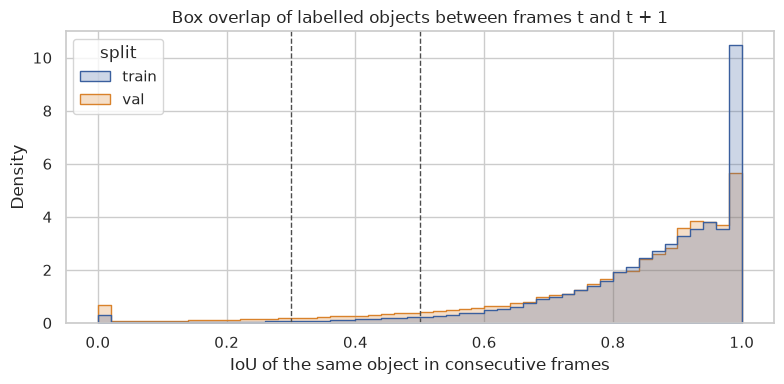

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(
    pairs.filter(pl.col("offset") == 1).to_dict(as_series=False),
    x="iou", hue="split", stat="density", common_norm=False, bins=50, element="step",
    palette=SPLIT_COLORS, ax=ax,
)
for link_iou in (0.3, 0.5):
    ax.axvline(link_iou, color="0.3", linestyle="--", linewidth=1)
ax.set(
    xlabel="IoU of the same object in consecutive frames",
    ylabel="Density",
    title="Box overlap of labelled objects between frames t and t + 1",
)
fig.tight_layout()

- Between consecutive frames, the median IoU of the same val object is 0.868 (train 0.897), and 90.1% of val pairs keep IoU ≥ 0.5 (95.6% ≥ 0.3). A one-frame IoU link follows almost every object.
- At $k = 5$ (the tuning frame step) the median falls to 0.506. Linking therefore needs every frame, which the val and test predictions have.
- The 10th percentile at $k = 1$ is 0.50 on val: fast or small objects drop out of a link at 0.5 and split into shorter tracks.

## 3. Method

`src/inference/temporal.py`, applied after the fusion of the members in `src/postprocess.py` (`[temporal]` in `config/postprocess/baseline.toml`):

1. **Linking.** In every clip and class, the detections of frame $t$ are matched one to one to those of frame $t + 1$, highest IoU first, if the IoU is at least `link_iou`. A matched detection continues the track of its predecessor; every other detection starts a new track. No score threshold: all up to 500 detections per frame are linked.
2. **Rescoring.** After Seq-NMS ([Han et al., 2016](https://arxiv.org/abs/1602.08465)), which rescores linked boxes with the average score of their sequence: a detection's new score is $(1 - w)\,s + w\,s_{\text{track}}$, where $s_{\text{track}}$ is the mean or the maximum score along its track and $w$ is `weight`. A detection confirmed in later or earlier frames rises toward its best frame; a detection seen in one frame keeps its score and so falls in the ranking.
3. **Box smoothing.** A box linked in both neighbouring frames becomes $(b_{t-1} + 2 b_t + b_{t+1}) / 4$, a binomial filter against frame-to-frame jitter that leaves constant motion unchanged.
4. **Causal variant** (`is_causal = true`). An online detector only has past frames: $s_{\text{track}}$ is the running mean or maximum up to frame $t$, and smoothing becomes $(b_{t-1} + 2 b_t) / 3$.

The settings of the reference model (`temporal_smooth_rtdetr`) and of the final ensemble were chosen on full val before the LB (`docs/pipeline.md` §10.2, §11.2):

In [5]:
pl.DataFrame(
    [
        {"config": name, **cfg["temporal"]}
        for name, cfg in (("temporal_smooth_rtdetr", reference_config), (FINAL, final_config))
    ]
)

config,enabled,link_iou,min_score,weight,statistic,is_causal,should_smooth_boxes
str,bool,f64,f64,f64,str,bool,bool
"""temporal_smooth_rtdetr""",true,0.3,0.0,0.5,"""max""",false,true
"""postprocess-ens_rtdetr4_frcnn2_yolo2_smooth""",true,0.5,0.0,0.5,"""max""",false,true


## 4. Ablation on the reference model

One change at a time from no temporal processing, on `rtdetr-baseline` (link IoU 0.3 unless stated). Settings were chosen on full val, the frames they are reported on, so the best rows are slightly optimistic; the halves A and B check that a gain repeats on disjoint clips. The seed spread of RT-DETRv2 training is 0.0094 mAP (`05_query_based.ipynb` §5), but post-processing is deterministic on fixed predictions, so differences here are not training noise; they can still be selection noise over 7 clips.

In [6]:
NO_TEMPORAL = {"temporal": {"enabled": False}}
RESCORING_ONLY = {"should_smooth_boxes": False}
ablation_settings = {
    "none": NO_TEMPORAL,
    "mean, w 0.5": {"temporal": RESCORING_ONLY | {"statistic": "mean"}},
    "max, w 0.25": {"temporal": RESCORING_ONLY | {"weight": 0.25}},
    "max, w 0.5": {"temporal": RESCORING_ONLY},
    "max, w 0.75": {"temporal": RESCORING_ONLY | {"weight": 0.75}},
    "max, w 1.0": {"temporal": RESCORING_ONLY | {"weight": 1.0}},
    "max, w 0.5, link 0.5": {"temporal": RESCORING_ONLY | {"link_iou": 0.5}},
    "max, w 0.5, link 0.7": {"temporal": RESCORING_ONLY | {"link_iou": 0.7}},
    "max, w 0.5 + smoothing": {},
    "causal mean, w 0.5": {"temporal": RESCORING_ONLY | {"is_causal": True, "statistic": "mean"}},
    "causal max, w 0.5": {"temporal": RESCORING_ONLY | {"is_causal": True}},
    "causal max, w 0.5 + causal smoothing": {"temporal": {"is_causal": True}},
}
SUMMARY_COLUMNS = ["map", "map50", "map75", "ap_small", "map_max_width_1920", "map_a", "map_b"]


def evaluate_settings(members: list[pl.DataFrame], base_config: dict, settings: dict) -> pl.DataFrame:
    table = evaluate_postprocess_settings(
        tables, members, base_config, list(settings.values()), clip_folds
    )
    return table.with_columns(setting=pl.Series(list(settings))).with_columns(
        (pl.col(c) - pl.col(c).first()).alias(f"delta_{c}") for c in ("map", "map_a", "map_b")
    )


ablation = evaluate_settings([reference_predictions], reference_config, ablation_settings)
ablation.select("setting", *SUMMARY_COLUMNS, "delta_map", "delta_map_a", "delta_map_b").with_columns(
    pl.selectors.float().round(4)
)

setting,map,map50,map75,ap_small,map_max_width_1920,map_a,map_b,delta_map,delta_map_a,delta_map_b
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""none""",0.3209,0.6027,0.3056,0.1334,0.2935,0.3386,0.2288,0.0,0.0,0.0
"""mean, w 0.5""",0.3242,0.6102,0.3075,0.1345,0.2937,0.347,0.2296,0.0033,0.0084,0.0008
"""max, w 0.25""",0.326,0.6115,0.311,0.1384,0.2984,0.3419,0.2339,0.0051,0.0033,0.0051
"""max, w 0.5""",0.3276,0.6124,0.314,0.1455,0.3007,0.3422,0.2371,0.0068,0.0037,0.0084
"""max, w 0.75""",0.3231,0.6,0.3119,0.1455,0.2973,0.3381,0.2353,0.0023,-0.0005,0.0065
"""max, w 1.0""",0.29,0.5387,0.2794,0.1258,0.2661,0.3072,0.2109,-0.0309,-0.0314,-0.0179
"""max, w 0.5, link 0.5""",0.3274,0.6118,0.3138,0.1463,0.3005,0.3426,0.2371,0.0066,0.004,0.0083
"""max, w 0.5, link 0.7""",0.3262,0.6087,0.313,0.1467,0.2993,0.3429,0.2343,0.0053,0.0043,0.0055
"""max, w 0.5 + smoothing""",0.3301,0.6144,0.3181,0.1462,0.3021,0.3444,0.2395,0.0092,0.0058,0.0107


- **Statistic.** Max beats mean at weight 0.5 (+0.0068 against +0.0033 mAP); mean gains on half A only (+0.0084, +0.0008 on B).
- **Weight.** 0.5 is the best weight: 0.25 gives +0.0051, 0.75 gives +0.0023, and 1.0 (score replaced by the track max) loses 0.0309. Every detection of a track then has the same score, so the ranking inside a frame no longer separates correct and wrong boxes of one track.
- **Link IoU.** 0.3 and 0.5 are equal (+0.0068, +0.0066); 0.7 gains less (+0.0053), as expected from §2.
- **Smoothing** adds +0.0024 on top of rescoring (AP75 0.3140 → 0.3181, AP50 +0.0020): mostly localisation.
- **Causal rescoring** keeps two thirds of the offline gain (+0.0045 against +0.0068 for max); causal mean is negative on half B.
- **Causal smoothing** loses 0.0089 and turns both halves negative: $(b_{t-1} + 2 b_t) / 3$ lags behind moving objects, and without the next frame nothing cancels the lag.

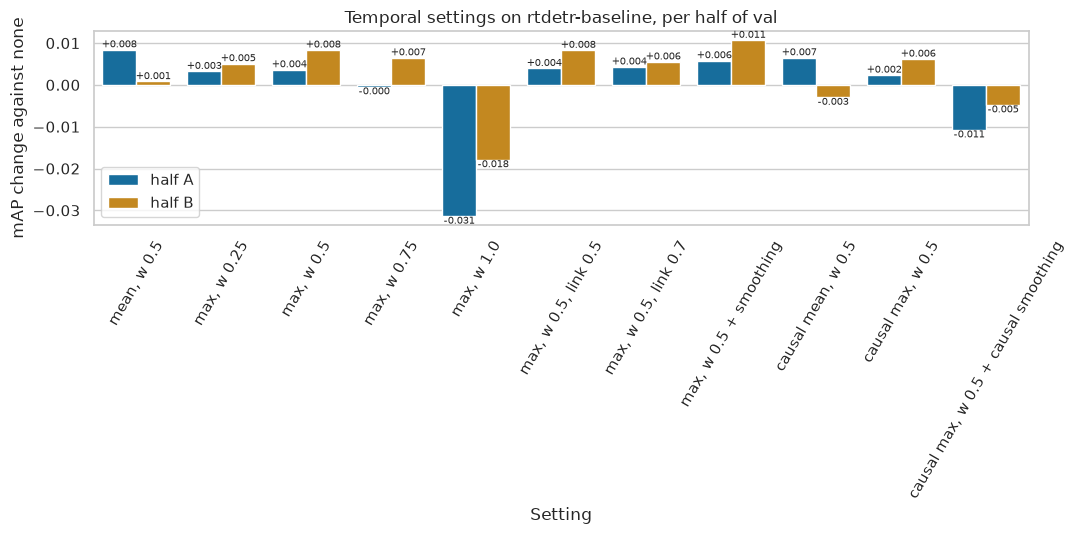

In [7]:
fig = plot_grouped_bars(
    ablation.filter(pl.col("setting") != "none")
    .unpivot(["delta_map_a", "delta_map_b"], index="setting", variable_name="half", value_name="delta")
    .with_columns(pl.col("half").replace({"delta_map_a": "half A", "delta_map_b": "half B"})),
    x="setting", y="delta", hue="half",
    labels=("Setting", "mAP change against none", "Temporal settings on rtdetr-baseline, per half of val"),
    value_format="{:+.3f}",
)
fig.axes[0].tick_params(axis="x", rotation=60)
fig.axes[0].legend(loc="lower left")
fig.set_size_inches(11, 5.5)
fig.tight_layout()

Every setting with max and weight 0.25 to 0.5 gains on both halves; the offline setting with smoothing gains most on both (+0.006 on A, +0.011 on B). The two losing settings lose on both halves too, so the ranking of settings repeats across disjoint clips.

## 5. Where the gain comes from

Four variants of the reference model: no temporal processing, offline rescoring (max, $w$ 0.5), offline rescoring plus smoothing (the `temporal_smooth_rtdetr` setting), and causal rescoring. First AP by class and by size, then detections and objects at the score threshold that maximizes F1 at IoU 0.5 (as the failure analysis of `02_two_stage.ipynb` to `05_query_based.ipynb`).

In [8]:
class_columns = [f"ap_{name}" for name in CLASS_NAMES]
ablation.filter(
    pl.col("setting").is_in(["none", "max, w 0.5", "max, w 0.5 + smoothing", "causal max, w 0.5"])
).select("setting", *class_columns).with_columns(pl.selectors.float().round(3))

setting,ap_person,ap_bicycle,ap_car,ap_van,ap_truck,ap_tricycle,ap_bus,ap_motor
str,f64,f64,f64,f64,f64,f64,f64,f64
"""none""",0.34,0.274,0.529,0.301,0.245,0.275,0.443,0.161
"""max, w 0.5""",0.34,0.285,0.528,0.31,0.257,0.287,0.453,0.161
"""max, w 0.5 + smoothing""",0.341,0.29,0.531,0.312,0.258,0.291,0.454,0.163
"""causal max, w 0.5""",0.34,0.283,0.53,0.309,0.253,0.284,0.442,0.162


Rescoring gains most on the rare classes with few confident detections: bicycle +0.016, tricycle +0.016, truck +0.013, van +0.011, bus +0.011 AP (offline with smoothing). Person, car, and motor change by at most 0.002; they already have the most confident and most numerous detections.

In [9]:
variant_settings = {
    "none": NO_TEMPORAL,
    "offline rescoring": ablation_settings["max, w 0.5"],
    "offline rescoring + smoothing": {},
    "causal rescoring": ablation_settings["causal max, w 0.5"],
}
variant_predictions = {
    name: postprocess_predictions(
        [reference_predictions], val_images, merge_config(reference_config, setting)
    )
    for name, setting in variant_settings.items()
}
variant_metrics = {
    name: evaluate_detections(tables, "val", predictions)
    for name, predictions in variant_predictions.items()
}
pl.DataFrame(
    [
        {"variant": name} | {key: round(m[key], 4) for key in ("map", "map50", "map75", "ap_small", "ap_medium", "ap_large")}
        for name, m in variant_metrics.items()
    ]
)

variant,map,map50,map75,ap_small,ap_medium,ap_large
str,f64,f64,f64,f64,f64,f64
"""none""",0.3209,0.6027,0.3056,0.1334,0.2719,0.4861
"""offline rescoring""",0.3276,0.6124,0.314,0.1455,0.2822,0.4897
"""offline rescoring + smoothing""",0.3301,0.6144,0.3181,0.1462,0.2844,0.4929
"""causal rescoring""",0.3253,0.6098,0.3106,0.1429,0.2771,0.4887


AP_small gains most in relative terms (0.1334 → 0.1462, +10%), AP_medium +0.0125, AP_large +0.0068. Small objects have the lowest single-frame scores, so the confirmation from other frames moves them up the most.

In [10]:
variant_matches = {
    name: match_detections(tables, "val", predictions)
    for name, predictions in tqdm(variant_predictions.items(), total=len(variant_predictions))
}
best_f1 = {name: find_best_f1_threshold(matches) for name, matches in variant_matches.items()}
# a variant without detections has no threshold; keeping every detection is then equivalent
thresholds = {name: values["threshold"] or 0.0 for name, values in best_f1.items()}
pl.DataFrame([{"variant": name} | values for name, values in best_f1.items()]).with_columns(
    pl.selectors.float().round(4)
)

  0%|          | 0/4 [00:00<?, ?it/s]

variant,threshold,precision,recall,f1
str,f64,f64,f64,f64
"""none""",0.4353,0.709,0.6773,0.6928
"""offline rescoring""",0.5147,0.7152,0.6613,0.6872
"""offline rescoring + smoothing""",0.5147,0.7161,0.6622,0.6881
"""causal rescoring""",0.5044,0.7202,0.6549,0.686


- The best-F1 threshold rises from 0.435 to 0.515 after rescoring, because scores of tracked detections move toward the track maximum.
- Best F1 itself does not improve (0.6928 → 0.6872 offline, 0.6860 causal). The mAP gain comes from the ranking over the whole score range (precision at every recall level), not from a better single operating point.

In [11]:
pl.concat(
    [
        count_error_categories(matches, thresholds[name]).with_columns(variant=pl.lit(name))
        for name, matches in variant_matches.items()
    ]
).pivot("variant", index="category", values="count")

category,none,offline rescoring,offline rescoring + smoothing,causal rescoring
str,i64,i64,i64,i64
"""correct""",71278,69598,69686,68926
"""duplicate""",684,1792,1810,1800
"""wrong_class""",9911,9891,9937,9582
"""poor_localisation""",9663,8731,8598,8523
"""background""",9001,7300,7281,6879
"""miss""",33962,35642,35554,36314


At each variant's own best-F1 threshold:
- background detections fall by 19% (9,001 → 7,300 offline, 6,879 causal) and poor localisations by 10% (9,663 → 8,731): one-frame false positives fall in the ranking;
- duplicates rise from 684 to 1,792: a second box on the same object forms its own track and is pulled up with it;
- misses rise from 33,962 to 35,642, because the threshold is higher.

In [12]:
def keep_matches_above(matches: DetectionMatches, threshold: float) -> DetectionMatches:
    # greedy matching in score order gives the same matches as matching only the kept detections
    return DetectionMatches(
        matches.detections.filter(pl.col("score") >= threshold),
        matches.objects.with_columns(
            pl.when(pl.col("matched_score") >= threshold).then(pl.col("matched_score"))
        ),
    )


pl.concat(
    [
        compute_recall_by_size(keep_matches_above(matches, thresholds[name])).with_columns(
            variant=pl.lit(name)
        )
        for name, matches in variant_matches.items()
    ]
).pivot("variant", index="size_bucket", values="recall").with_columns(pl.selectors.float().round(4))

size_bucket,none,offline rescoring,offline rescoring + smoothing,causal rescoring
str,f64,f64,f64,f64
"""all""",0.6773,0.6613,0.6622,0.6549
"""small""",0.5045,0.4657,0.4655,0.4598
"""medium""",0.6973,0.6833,0.6845,0.6772
"""large""",0.8491,0.8597,0.8604,0.8509


At the operating point, recall of small objects falls from 0.505 to 0.466, while recall of large objects rises from 0.849 to 0.860. With one threshold for all sizes, the higher threshold after rescoring costs the small objects whose tracks stay weak. The AP_small gain above is a ranking gain, not a recall gain at this threshold.

In [13]:
def is_found(name: str) -> pl.Series:
    threshold = thresholds[name]
    return variant_matches[name].objects["matched_score"].fill_null(-1.0) >= threshold


found_before = is_found("none")
pl.DataFrame(
    [
        {
            "variant": name,
            "found by both": (found_before & is_found(name)).sum(),
            "recovered": (~found_before & is_found(name)).sum(),
            "lost": (found_before & ~is_found(name)).sum(),
        }
        for name in variant_settings
        if name != "none"
    ]
)

variant,found by both,recovered,lost
str,i64,i64,i64
"""offline rescoring""",68102,1496,3176
"""offline rescoring + smoothing""",67856,1830,3422
"""causal rescoring""",67814,1112,3464


Offline rescoring recovers 1,496 objects missed without it and loses 3,176 at its own threshold; with smoothing 1,830 and 3,422. The net loss at one threshold agrees with the F1 table; mAP integrates over all thresholds and gains.

## 6. Example track

A track of the reference model with an object that offline rescoring recovers: below the best-F1 threshold without temporal processing, matched above it after rescoring. The track is chosen automatically: the longest track with the most recovered detections of a small object (area below 32² px²). Rescoring only, so the boxes are the original ones.

In [14]:
TEMPORAL = reference_config["temporal"]
tracked = assign_tracks(reference_predictions, val_images, TEMPORAL["link_iou"], TEMPORAL["min_score"])
tracked = tracked.with_columns(raw_score=pl.col("score"))
offline = rescore_tracks(tracked, TEMPORAL["weight"], TEMPORAL["statistic"], is_causal=False)
causal = rescore_tracks(tracked, TEMPORAL["weight"], TEMPORAL["statistic"], is_causal=True)
track_scores = offline.join(
    causal.select("track_id", "frame_id", pl.col("score").alias("causal_score")),
    on=["track_id", "frame_id"],
)
correct_after = variant_matches["offline rescoring"].detections.filter(
    pl.col("category") == "correct"
).select("image_id", "class_id", *BOX_COLUMNS, "score")
recovered = track_scores.join(
    correct_after, on=["image_id", "class_id", *BOX_COLUMNS, "score"]
).filter(
    pl.col("raw_score") < thresholds["none"],
    pl.col("score") >= thresholds["offline rescoring"],
    pl.col("w") * pl.col("h") < 32**2,
)
example_track_id = (
    recovered.group_by("track_id").len().join(
        track_scores.group_by("track_id").len().rename({"len": "track_length"}), on="track_id"
    ).sort("len", "track_length", "track_id", descending=[True, True, False])["track_id"][0]
)
example = track_scores.filter(pl.col("track_id") == example_track_id).sort("frame_id")
example.select(
    "clip", pl.col("class_id").replace_strict(dict(enumerate(CLASS_NAMES))).alias("class"),
    pl.len().alias("frames"), pl.col("frame_id").min().alias("first_frame"),
    pl.col("raw_score").min().round(3).alias("min_raw_score"),
    pl.col("raw_score").max().round(3).alias("max_raw_score"),
    (pl.col("w") * pl.col("h")).sqrt().median().round(1).alias("median_sqrt_area_px"),
).head(1)

clip,class,frames,first_frame,min_raw_score,max_raw_score,median_sqrt_area_px
str,str,u32,i64,f64,f64,f64
"""uav0000182_00000_v""","""car""",108,91,0.145,0.653,27.7


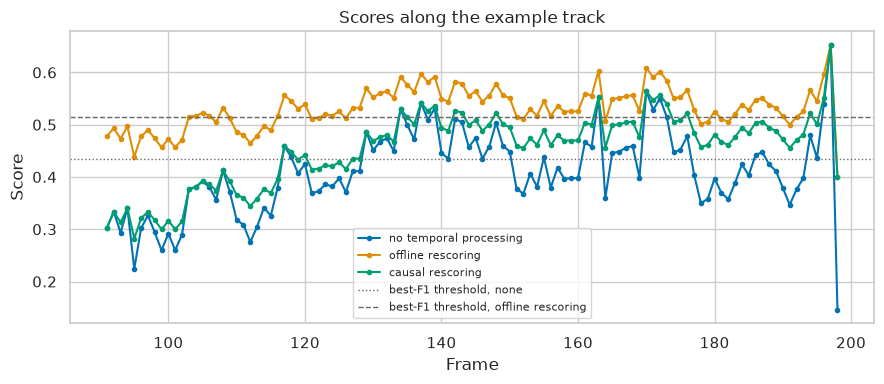

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
for column, label in (
    ("raw_score", "no temporal processing"),
    ("score", "offline rescoring"),
    ("causal_score", "causal rescoring"),
):
    ax.plot(example["frame_id"], example[column], marker=".", label=label)
for name, linestyle in (("none", ":"), ("offline rescoring", "--")):
    ax.axhline(thresholds[name], color="0.4", linestyle=linestyle, linewidth=1,
               label=f"best-F1 threshold, {name}")
ax.set(xlabel="Frame", ylabel="Score", title="Scores along the example track")
ax.legend(fontsize=8)
fig.tight_layout()

A small car (median √area 27.7 px) on `uav0000182`, the val clip with the smallest objects, tracked over 108 frames. Without temporal processing its score oscillates between 0.22 and 0.55 and falls below the best-F1 threshold in most frames. Offline rescoring lifts it toward the track maximum (0.653), above its threshold for most of the track. The causal score rises only after the first high-scoring frames (from about frame 117) and stays below the offline score before them. The last frame (0.145) is a weak detection linked at the end of the track.

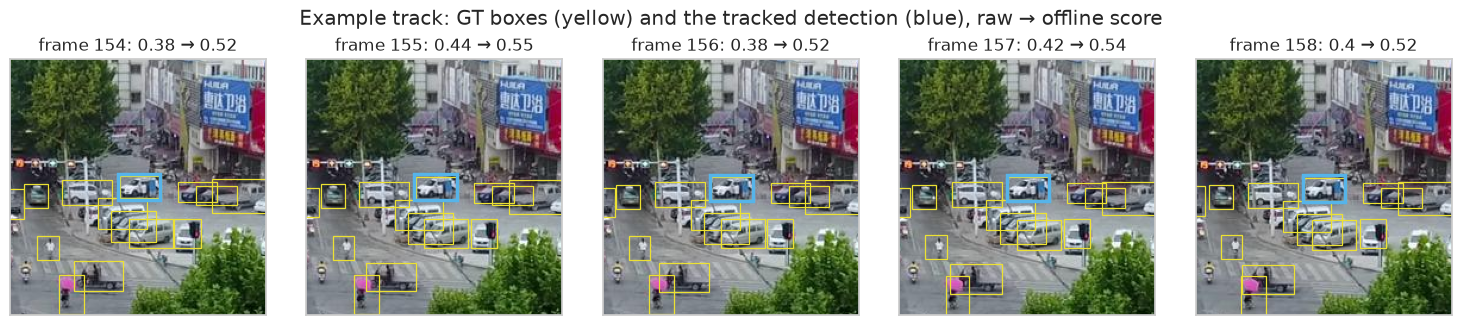

In [16]:
recovered_frames = recovered.filter(pl.col("track_id") == example_track_id)["frame_id"].sort()
centre = recovered_frames[len(recovered_frames) // 2]
window = example.filter((pl.col("frame_id") - centre).abs() <= 2)
centre_row = window.filter(pl.col("frame_id") == centre).row(0, named=True)
frame_size = val_images.filter(pl.col("image_id") == centre_row["image_id"]).select("width", "height").row(0)
x0, y0, side = compute_context_crop(
    tuple(centre_row[c] for c in BOX_COLUMNS), frame_size, context_scale=6.0, min_side=160
)
frames = window.join(val_images.select("image_id", "file_path"), on="image_id").with_columns(
    panel_title=pl.format(
        "frame {}: {} → {}",
        "frame_id",
        pl.col("raw_score").round(2),
        pl.col("score").round(2),
    )
).sort("frame_id")
fig = plot_frame_sequence(
    frames,
    tables.objects.filter(pl.col("split") == "val"),
    window,
    (x0, y0),
    (side, side),
    "Example track: GT boxes (yellow) and the tracked detection (blue), raw → offline score",
)

Five consecutive frames around a recovered detection: the box stays on the same car, and its raw scores of 0.38 to 0.44 become 0.52 to 0.55.

## 7. Other models and the final ensemble

The setting of the final ensemble (max, $w$ 0.5, link IoU 0.5, smoothing), unchanged, on the best single model, one model of each other family, and the WBF of the eight members of the final ensemble D (`ens_rtdetr4_frcnn2_yolo2_smooth`) before its temporal step. Columns: no temporal processing, offline rescoring and smoothing, and the causal variants.

In [17]:
transfer_config = merge_config(reference_config, {"temporal": final_config["temporal"]})
transfer_settings = {
    "none": NO_TEMPORAL,
    "offline": {},
    "causal rescoring": {"temporal": {"is_causal": True, "should_smooth_boxes": False}},
    "causal rescoring + causal smoothing": {"temporal": {"is_causal": True}},
}
fused_final = postprocess_predictions(
    [load_val_predictions(member) for member in final_config["members"]],
    val_images,
    merge_config(final_config, NO_TEMPORAL),
)
transfer_members = {
    "rtdetr-infer_recipe_step2_det500": load_val_predictions("rtdetr-infer_recipe_step2_det500"),
    "faster_rcnn-giou_loss": load_val_predictions("faster_rcnn-giou_loss"),
    "retinanet-baseline": load_val_predictions("retinanet-baseline"),
    "yolo-baseline": load_val_predictions("yolo-baseline"),
    "ensemble D (WBF of 8 members)": fused_final,
}
transfer = pl.concat(
    [
        evaluate_settings([predictions], transfer_config, transfer_settings).with_columns(
            model=pl.lit(model)
        )
        for model, predictions in tqdm(transfer_members.items())
    ]
)
transfer.select("model", "setting", "map", "map75", "ap_small", "delta_map", "delta_map_a", "delta_map_b").with_columns(
    pl.selectors.float().round(4)
)

  0%|          | 0/5 [00:00<?, ?it/s]

model,setting,map,map75,ap_small,delta_map,delta_map_a,delta_map_b
str,str,f64,f64,f64,f64,f64,f64
"""rtdetr-infer_recipe_step2_det500""","""none""",0.3417,0.329,0.1403,0.0,0.0,0.0
"""rtdetr-infer_recipe_step2_det500""","""offline""",0.3478,0.3384,0.1648,0.0061,0.0048,0.0084
"""rtdetr-infer_recipe_step2_det500""","""causal rescoring""",0.3444,0.3331,0.1573,0.0027,0.001,0.0077
"""rtdetr-infer_recipe_step2_det500""","""causal rescoring + causal smoothing""",0.3357,0.3188,0.1546,-0.006,-0.007,-0.0017
"""faster_rcnn-giou_loss""","""none""",0.3066,0.265,0.1203,0.0,0.0,0.0
"""faster_rcnn-giou_loss""","""offline""",0.3192,0.2864,0.1374,0.0125,0.013,0.0119
"""faster_rcnn-giou_loss""","""causal rescoring""",0.3124,0.2715,0.1248,0.0058,0.0064,0.0075
"""faster_rcnn-giou_loss""","""causal rescoring + causal smoothing""",0.3071,0.2623,0.1253,0.0005,0.0017,0.0018
"""retinanet-baseline""","""none""",0.2689,0.2559,0.078,0.0,0.0,0.0


- **Offline rescoring and smoothing** gains on every model and on both halves of val: RT-DETRv2 M1 +0.0061, Faster R-CNN +0.0125, RetinaNet +0.0174, YOLO11s +0.0082, the eight-member ensemble +0.0118 (half B +0.026). The weaker the single-frame scores, the larger the gain (RetinaNet).
- **Causal rescoring** keeps 44% to 80% of the offline gain (M1 +0.0027, ensemble +0.0094) and gains on both halves for every model.
- **Causal smoothing** removes most or all of the causal gain on every model (−0.006 to +0.005 against no temporal processing). An online pipeline should rescore along past frames and keep the boxes.
- AP_small gains on every model, most on M1 (0.1403 → 0.1648).

## 8. Public leaderboard and cost

The only single-factor LB check of the temporal step is `postprocess-temporal_smooth_rtdetr` against `rtdetr-baseline` (submitted before the final selection); the final ensemble includes the step. Cost: wall time of rescoring and smoothing all val frames of the fused ensemble on the laptop CPU (the step needs no GPU; GPU speeds in `results.csv` are measured on the PC).

In [18]:
results.filter(
    pl.col("experiment").is_in([REFERENCE, "postprocess-temporal_smooth_rtdetr", FINAL])
).select("experiment", "map", "map_max_width_1920", "ap_small", "public_lb").with_columns(
    pl.selectors.float().round(4)
)

experiment,map,map_max_width_1920,ap_small,public_lb
str,f64,f64,f64,f64
"""rtdetr-baseline""",0.3209,0.2935,0.1334,0.2563
"""postprocess-temporal_smooth_rtdetr""",0.3301,0.3021,0.1462,0.2688
"""postprocess-ens_rtdetr4_frcnn2_yolo2_smooth""",0.3859,0.3611,0.188,0.2981


In [19]:
start = time.perf_counter()
postprocess_predictions([fused_final], val_images, transfer_config)
elapsed = time.perf_counter() - start
pl.DataFrame(
    {
        "frames": [val_images.height],
        "detections": [fused_final.height],
        "seconds": [round(elapsed, 1)],
        "ms_per_frame_laptop_cpu": [round(1000 * elapsed / val_images.height, 2)],
    }
)

frames,detections,seconds,ms_per_frame_laptop_cpu
i64,i64,f64,f64
2593,1296500,7.3,2.83


- **LB, one factor.** On the public LB, `temporal_smooth_rtdetr` scores 0.2688 against 0.2563 for `rtdetr-baseline` (+0.0125, val +0.0092): the gain transfers to the test clips. This is the only single-factor LB check; the final ensemble includes the step, and its version without the step was not submitted.
- **Cost.** Linking, rescoring, and smoothing all 2,593 val frames of the ensemble (1.3 M detections) take 7.3 s on the laptop CPU, 2.8 ms per frame, against 53 ms per frame of RT-DETRv2 inference on the PC GPU.

## 9. Conclusions

**Results**

- **Data.** 90% of val objects keep IoU ≥ 0.5 between consecutive frames (median 0.868), so greedy one-to-one IoU linking per class follows almost every object (§2).
- **Method and settings.** Rescoring toward the track maximum with weight 0.5 is best; smoothing boxes with both neighbours adds mainly AP75. Weight 1.0 and causal smoothing lose on both halves of val (§4).
- **Gain.** +0.0092 mAP on `rtdetr-baseline`, +0.0061 to +0.0174 on one model of each family, +0.0118 on the final ensemble, positive on both halves of val in every case; AP_small gains most in relative terms (§4, §7).
- **Causal variant.** Rescoring with past frames only keeps 44% to 80% of the offline gain; smoothing with past frames only loses (§4, §7).
- **Mechanism.** At a fixed threshold, rescoring removes 19% of background detections but doubles duplicates and lowers best F1 slightly; the mAP gain is a ranking gain over all thresholds (§5).
- **Test.** +0.0125 on the public LB for the single-factor submission; 2.8 ms per frame on a laptop CPU (§8).

**Hypotheses, not tested**

- Duplicates rise because duplicate boxes form their own tracks; suppressing tracks that overlap a stronger track in most frames (track-level NMS, as in Seq-NMS) could remove them.
- Causal smoothing could work with a motion model (constant velocity or camera-motion compensation by homography) instead of plain averaging; a one-step constant-velocity version was tried only in a quick laptop test and also lost mAP, so it is not included.
- Rescoring could pass the class along a track (majority class), which may help the wrong-class errors between car and van.